# 05 — Phúc: so sánh mô hình, bản dễ đọc (v2)

Đọc và chạy từ trên xuống: **đọc bảng → chọn X/y → tạo model → fit theo fold → dự đoán → chấm → lưu**.

Mô hình được khai báo trực tiếp trong notebook. `GridSearchCV` thay cho bộ tìm kiếm tự viết; không gọi `run_experiments`, `fit_candidate` hay `save_week5_results`.

**Giao thức v2:** vẫn giữ 3 outer domain folds và chọn tham số bằng 2 inner group folds. AP là tiêu chí chính. SVM dùng decision score + `.predict()`, không calibration; LR/MLP/boosting dùng probability + `.predict()`. Vì vậy v2 là thí nghiệm mới, không thay tên các kết quả v1 đã chạy.

Run All sẽ **train lại** và cập nhật file `05_readable_*`. Official test không fit/predict/score. Brand features và Teacher cuối cùng vẫn chờ bàn giao/review.

## 1. Thư viện và thiết lập
`SEED` giúp lặp lại; `FEATURES` là các cột đưa vào model. Khi học nên xem trực tiếp biến trong từng cell, không cần đọc code xuất báo cáo cũ.

In [1]:
from pathlib import Path
import sys
import hashlib
import json
import platform
from datetime import datetime, timezone
from importlib.metadata import version
import warnings

import joblib
import nbformat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix,
                             precision_recall_curve, ConfusionMatrixDisplay)
from threadpoolctl import threadpool_limits

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from phishguard_vn.splits import audit_domain_overlap
DATA = PROJECT_ROOT / "data/interim"
TABLES = PROJECT_ROOT / "reports/tables"
FIGURES = PROJECT_ROOT / "reports/figures"
MODELS_DIR = PROJECT_ROOT / "models"
for folder in [TABLES, FIGURES, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
FEATURE_SET = "lexical_12"
FEATURE_FILE = DATA / "03_matrix_X_features.csv"
FEATURES = ["url_len", "dom_len", "is_ip", "subdom_cnt", "letter_cnt", "digit_cnt",
            "dot_cnt", "dash_cnt", "under_cnt", "slash_cnt", "entropy", "path_len"]
# Giới hạn CPU; đây không phải một bước học máy.
CPU_LIMIT = threadpool_limits(limits=1)
print("Project:", PROJECT_ROOT)
print("Số feature:", len(FEATURES))


Project: D:\PhishGuardVN
Số feature: 12


## 2. Đọc bốn bảng bàn giao
- Khiêm: core có nhãn và official split.
- Hy: feature và domain.
- Hưng: `id, fold_id` của các mẫu train.

ID là khóa nối, không phải feature. Metadata dùng kiểm tra/phân tích, không đưa vào X.

In [2]:
core = pd.read_csv(DATA / "core_gold_silver.csv", dtype={"id": "string"}, low_memory=False)
features = pd.read_csv(FEATURE_FILE, dtype={"id": "string"})
domains = pd.read_csv(DATA / "03_registrable_domains.csv", dtype={"id": "string"})
folds = pd.read_csv(DATA / "02_group_folds_train.csv", dtype={"id": "string"})

for table in [core, features, domains, folds]:
    assert table["id"].notna().all() and table["id"].str.strip().ne("").all(), "ID thiếu/rỗng"
    assert table["id"].is_unique, "ID trùng"
assert set(features.columns) == {"id", *FEATURES}, "X sai schema"
assert not set(FEATURES) & {"id", "label", "target", "source", "tier", "split", "registrable_domain"}
assert np.isfinite(features[FEATURES].to_numpy(float)).all(), "Feature có NaN/Inf"
assert core["label"].isin(["benign", "phishing"]).all()
assert core["tier"].isin(["gold", "silver"]).all()
assert core["split"].isin(["train", "val", "test"]).all()
assert set(core["id"]) == set(domains["id"])

metadata = core[["id", "label", "tier", "split"]].merge(
    domains[["id", "registrable_domain"]], on="id", validate="one_to_one")
audit = audit_domain_overlap(metadata)
assert audit["status"] != "overlap_detected", "Domain trùng giữa official splits"
assert audit["unknown_domain_rows"] == int(metadata["registrable_domain"].isna().sum())
assert set(features["id"]) == set(metadata.loc[metadata["registrable_domain"].notna(), "id"]), "Coverage feature khác core đủ điều kiện"
assert list(folds.columns) == ["id", "fold_id"]
assert pd.api.types.is_integer_dtype(folds["fold_id"]) and set(folds["fold_id"]) == {0, 1, 2}
assert set(folds["id"]) == set(metadata.loc[metadata["split"].eq("train") & metadata["registrable_domain"].notna(), "id"])

# Từ đây chỉ giữ train/validation cho mô hình; không tạo X_test hay y_test.
eligible = features.merge(metadata, on="id", validate="one_to_one")
train = eligible.loc[eligible["split"].eq("train")].merge(folds, on="id", validate="one_to_one").sort_values("id").reset_index(drop=True)
validation = eligible.loc[eligible["split"].eq("val")].sort_values("id").reset_index(drop=True)
train["target"] = train["label"].map({"benign": 0, "phishing": 1})
validation["target"] = validation["label"].map({"benign": 0, "phishing": 1})
assert train.groupby("registrable_domain")["fold_id"].nunique().eq(1).all()
assert train["target"].nunique() == 2 and validation["target"].nunique() == 2
print("Train:", len(train), "| Validation:", len(validation))
display(train.groupby(["fold_id", "label"]).size().unstack(fill_value=0))
display(train[["id", *FEATURES, "target"]].head())


Train: 13078 | Validation: 1585


label,benign,phishing
fold_id,,
0,3668,691
1,3668,691
2,3668,692


,id,url_len,dom_len,is_ip,subdom_cnt,letter_cnt,digit_cnt,dot_cnt,dash_cnt,under_cnt,slash_cnt,entropy,path_len,target
0,0004e6cc-1580-503e-8ac9-b8039a0ebee9,35.0,12.0,0.0,2.0,31.0,0.0,4.0,0.0,0.0,0.0,3.397020,0.0,0
1,00091f3e-1d47-52cb-b645-2a4c91788ba0,17.0,17.0,0.0,0.0,14.0,0.0,2.0,1.0,0.0,0.0,3.499228,0.0,0
2,000c7930-c2e6-52c8-aee2-1cd639aadfc4,7.0,7.0,0.0,0.0,6.0,0.0,1.0,0.0,0.0,0.0,2.807355,0.0,0
3,000f5203-2e84-50ed-b16b-738c5d96c199,10.0,10.0,0.0,0.0,8.0,0.0,2.0,0.0,0.0,0.0,2.921928,0.0,0
4,001277ac-004d-5d93-9e5c-b718397e5ddd,13.0,13.0,0.0,0.0,12.0,0.0,1.0,0.0,0.0,0.0,3.026987,0.0,0


## 3. Khai báo mô hình ngay tại đây
Scaler chỉ học khi gọi `.fit()` trên pipeline. MLP và HistGB tắt random-validation early stopping. Hai LR giữ C=1 làm đối chứng E1.

SVM không có probability ở phiên bản này: AP dùng `decision_function`; nhãn lấy từ `.predict()`. Không diễn giải decision score thành phần trăm nguy cơ.

In [3]:
lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(C=1.0, max_iter=2000, random_state=SEED))
])
lr_balanced = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000, random_state=SEED))
])
svm = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="rbf", gamma="scale", cache_size=256))
])
mlp = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(alpha=0.001, max_iter=1000, batch_size=256,
                            early_stopping=False, n_iter_no_change=20, random_state=SEED))
])
boosting = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1,
                                        l2_regularization=1.0, early_stopping=False,
                                        random_state=SEED)

models = {"logistic_regression": lr, "logistic_regression_balanced": lr_balanced,
          "svm_rbf": svm, "mlp": mlp, "hist_gradient_boosting": boosting}
# Chỉ thử hai cấu hình mỗi họ; không thêm grid vì nhìn validation/test.
param_grids = {"logistic_regression": {}, "logistic_regression_balanced": {},
               "svm_rbf": {"model__C": [0.5, 2.0]},
               "mlp": {"model__hidden_layer_sizes": [(32,), (32, 16)]},
               "hist_gradient_boosting": {"max_leaf_nodes": [7, 15]}}


## 4. Đi từng bước với LR và một fold
Đây là ví dụ nhỏ để hiểu `.fit()` / `.predict()`, chưa phải kết luận chung. Cell 6 sẽ đánh giá đủ cả ba fold. Model không đọc nhãn của fold giữ lại khi học.

In [4]:
fitting = train.loc[train["fold_id"].ne(0)]
held_out = train.loc[train["fold_id"].eq(0)]
X_train, y_train = fitting[FEATURES], fitting["target"]
X_holdout, y_holdout = held_out[FEATURES], held_out["target"]

lr.fit(X_train, y_train)
predictions = lr.predict(X_holdout)
scores = lr.predict_proba(X_holdout)[:, 1]
print("LR fold 0 — F1:", f1_score(y_holdout, predictions))
print("LR fold 0 — AP:", average_precision_score(y_holdout, scores))


LR fold 0 — F1: 0.4883268482490272
LR fold 0 — AP: 0.6123051168918701


## 5. Một hàm chấm điểm ngắn, đọc được ngay
AP nhận cả probability lẫn SVM decision score. Confusion/F1 dùng nhãn từ `.predict()`. FPR là FP / số benign; precision là TP / số cảnh báo. Không dùng accuracy một mình.

In [5]:
def calculate_metrics(y_true, predicted, score):
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y_true, predicted),
            "precision_phishing": precision_score(y_true, predicted, zero_division=0),
            "recall_phishing": recall_score(y_true, predicted, zero_division=0),
            "f1_phishing": f1_score(y_true, predicted, zero_division=0),
            "pr_auc": average_precision_score(y_true, score),
            "false_positive_rate": fp / (fp + tn),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}


## 6. Đánh giá cả ba outer folds
Đọc vòng lặp từ trên xuống:
1. Giữ lại một fold để chấm, học trên hai fold còn lại.
2. Nếu có grid, `GridSearchCV` thử tham số bằng **inner Group CV chỉ trong phần fitting**; scaler cũng được fit lại bên trong từng lượt.
3. Lấy model đã fit, predict outer fold, tính metrics và giữ ID.

`clone()` chỉ tạo model mới cùng cấu hình, không mang kiến thức của lượt trước. Nếu không hội tụ thì dừng để kiểm tra; không che warning rồi công bố kết quả.

In [6]:
cv_rows, cv_prediction_tables, parameter_rows = [], [], []
for model_name, model in models.items():
    for fold_id in [0, 1, 2]:
        fitting = train.loc[train["fold_id"].ne(fold_id)]
        held_out = train.loc[train["fold_id"].eq(fold_id)]
        X_train, y_train = fitting[FEATURES], fitting["target"]
        X_holdout, y_holdout = held_out[FEATURES], held_out["target"]
        groups = fitting["registrable_domain"]
        assert set(groups).isdisjoint(held_out["registrable_domain"])
        assert y_train.nunique() == y_holdout.nunique() == 2

        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            if param_grids[model_name]:
                inner_cv = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=SEED)
                inner_splits = list(inner_cv.split(X_train, y_train, groups))
                for fit_index, score_index in inner_splits:
                    assert y_train.iloc[fit_index].nunique() == y_train.iloc[score_index].nunique() == 2
                    assert set(groups.iloc[fit_index]).isdisjoint(groups.iloc[score_index])
                search = GridSearchCV(clone(model), param_grids[model_name],
                                      scoring="average_precision", cv=inner_splits,
                                      n_jobs=1, error_score="raise", refit=True)
                search.fit(X_train, y_train)
                fitted_model = search.best_estimator_
                best_params = search.best_params_
            else:
                fitted_model = clone(model)
                fitted_model.fit(X_train, y_train)
                best_params = {}

        predicted = fitted_model.predict(X_holdout)
        if model_name == "svm_rbf":
            score = fitted_model.decision_function(X_holdout)
            score_kind = "decision_function"
        else:
            score = fitted_model.predict_proba(X_holdout)[:, 1]
            score_kind = "probability"
        cv_rows.append({"model": model_name, "fold_id": fold_id,
                        **calculate_metrics(y_holdout, predicted, score)})
        cv_prediction_tables.append(pd.DataFrame({
            "id": held_out["id"].to_numpy(), "model": model_name, "fold_id": fold_id,
            "evaluation_partition": "group_cv", "true_label": y_holdout.to_numpy(),
            "predicted_label": predicted, "score": score, "score_kind": score_kind}))
        parameter_rows.append({"model": model_name, "context": fold_id,
                               "parameters": json.dumps(best_params, sort_keys=True)})
        print(model_name, "fold", fold_id, "AP =", round(cv_rows[-1]["pr_auc"], 4))

cv_metrics = pd.DataFrame(cv_rows)
cv_predictions = pd.concat(cv_prediction_tables, ignore_index=True)


logistic_regression fold 0 AP = 0.6123
logistic_regression fold 1 AP = 0.5833
logistic_regression fold 2 AP = 0.5869
logistic_regression_balanced fold 0 AP = 0.5587


logistic_regression_balanced fold 1 AP = 0.5418
logistic_regression_balanced fold 2 AP = 0.5727


svm_rbf fold 0 AP = 0.6728


svm_rbf fold 1 AP = 0.6094


svm_rbf fold 2 AP = 0.6456


mlp fold 0 AP = 0.7153


mlp fold 1 AP = 0.6929


mlp fold 2 AP = 0.6894


hist_gradient_boosting fold 0 AP = 0.707


hist_gradient_boosting fold 1 AP = 0.7146


hist_gradient_boosting fold 2 AP = 0.6721


## 7. So sánh và chọn bằng AP
Đây là mean/std của từng fold, không phải AP tính từ OOF gộp. Chọn bằng mean AP; hòa thì mean F1, FPR thấp hơn, cuối cùng tên model. Chọn giữa nhiều họ bằng chính CV vẫn có selection bias; official test được giữ lại cho đánh giá cuối sau khi chốt.

Đừng chọn model chỉ vì một con số: đọc FPR và Recall cùng nhau.

In [7]:
metric_names = ["pr_auc", "precision_phishing", "recall_phishing", "f1_phishing", "false_positive_rate"]
summary = cv_metrics.groupby("model")[metric_names].agg(["mean", "std"])
summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
summary = summary.reset_index().sort_values(
    ["pr_auc_mean", "f1_phishing_mean", "false_positive_rate_mean", "model"],
    ascending=[False, False, True, True]).reset_index(drop=True)
selected_model = summary.loc[0, "model"]
display(summary)
print("Ứng viên lexical-only:", selected_model)


,model,pr_auc_mean,pr_auc_std,precision_phishing_mean,precision_phishing_std,recall_phishing_mean,recall_phishing_std,f1_phishing_mean,f1_phishing_std,false_positive_rate_mean,false_positive_rate_std
0,mlp,0.699200,0.014049,0.798302,0.024278,0.481222,0.048225,0.598947,0.033277,0.023173,0.005308
1,hist_gradient_boosting,0.697899,0.022626,0.819157,0.003361,0.482176,0.032179,0.606561,0.024645,0.020084,0.001774
2,svm_rbf,0.642641,0.031806,0.845691,0.037716,0.418524,0.018516,0.559552,0.016935,0.014540,0.004365
3,logistic_regression,0.594173,0.015811,0.729997,0.029375,0.326929,0.045412,0.449986,0.043073,0.022992,0.005331
4,logistic_regression_balanced,0.557744,0.015502,0.344914,0.012513,0.807131,0.008863,0.483148,0.010705,0.289440,0.019357


Ứng viên lexical-only: mlp


## 8. Chọn cấu hình cuối trên toàn train, rồi chấm validation bổ sung
Các tham số ở đây được chọn lại bằng Group CV **chỉ trên toàn train**; model được fit toàn train, không thêm validation. `selected_model` đã được chọn ở cell 7 và không đổi theo bảng validation.

Vòng lặp tương tự cell 6, nhưng không giữ lại outer fold nữa. Tách thành cell riêng để nhìn rõ model nào sẽ được lưu.

In [8]:
trained_models, validation_rows, validation_prediction_tables = {}, [], []
X_train, y_train = train[FEATURES], train["target"]
for model_name, model in models.items():
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        if param_grids[model_name]:
            inner_cv = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=SEED)
            inner_splits = list(inner_cv.split(X_train, y_train, train["registrable_domain"]))
            for fit_index, score_index in inner_splits:
                assert y_train.iloc[fit_index].nunique() == y_train.iloc[score_index].nunique() == 2
                assert set(train.iloc[fit_index]["registrable_domain"]).isdisjoint(train.iloc[score_index]["registrable_domain"])
            search = GridSearchCV(clone(model), param_grids[model_name], scoring="average_precision",
                                  cv=inner_splits, n_jobs=1, error_score="raise", refit=True)
            search.fit(X_train, y_train)
            fitted_model, best_params = search.best_estimator_, search.best_params_
        else:
            fitted_model = clone(model)
            fitted_model.fit(X_train, y_train)
            best_params = {}
    trained_models[model_name] = fitted_model
    parameter_rows.append({"model": model_name, "context": "full_train",
                           "parameters": json.dumps(best_params, sort_keys=True)})

    predicted = fitted_model.predict(validation[FEATURES])
    if model_name == "svm_rbf":
        score = fitted_model.decision_function(validation[FEATURES])
        score_kind = "decision_function"
    else:
        score = fitted_model.predict_proba(validation[FEATURES])[:, 1]
        score_kind = "probability"
    validation_rows.append({"model": model_name,
                            **calculate_metrics(validation["target"], predicted, score)})
    validation_prediction_tables.append(pd.DataFrame({
        "id": validation["id"].to_numpy(), "model": model_name,
        "evaluation_partition": "official_validation", "true_label": validation["target"].to_numpy(),
        "predicted_label": predicted, "score": score, "score_kind": score_kind}))

validation_metrics = pd.DataFrame(validation_rows)
validation_predictions = pd.concat(validation_prediction_tables, ignore_index=True)
display(validation_metrics)


,model,accuracy,precision_phishing,recall_phishing,f1_phishing,pr_auc,false_positive_rate,tn,fp,fn,tp
0,logistic_regression,0.970347,0.255319,0.500000,0.338028,0.293308,0.022422,1526,35,12,12
1,logistic_regression_balanced,0.591798,0.034380,0.958333,0.066378,0.274431,0.413837,915,646,1,23
2,svm_rbf,0.980442,0.360000,0.375000,0.367347,0.263879,0.010250,1545,16,15,9
3,mlp,0.969085,0.244898,0.500000,0.328767,0.431387,0.023703,1524,37,12,12
4,hist_gradient_boosting,0.976025,0.325000,0.541667,0.406250,0.433845,0.017297,1534,27,11,13


## 9. Biểu đồ và các lỗi thật
Đường PR dưới dùng OOF gộp để minh họa, không thay mean AP theo fold khi chọn model. Score của SVM là margin; các fold có thể có thang score khác nhau. Ví dụ lỗi giữ tối đa 2 FP và 2 FN mỗi fold, không chỉ lấy fold 0. Nhãn/nguồn là thông tin của dataset, chưa xác minh website hiện tại.

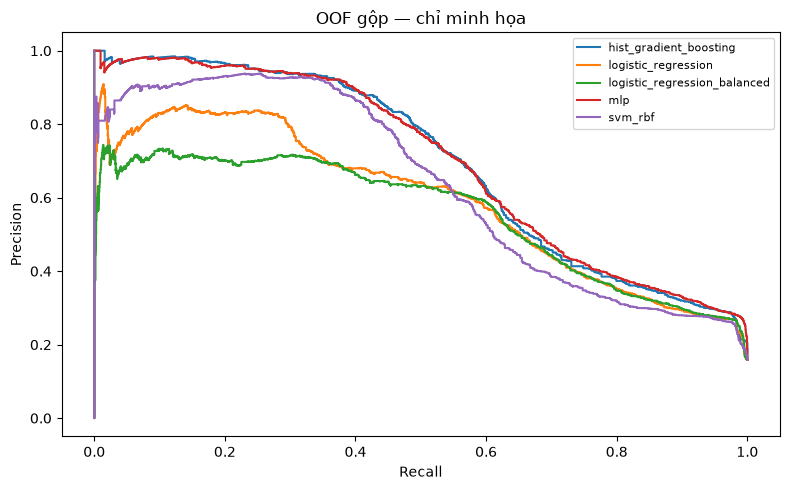

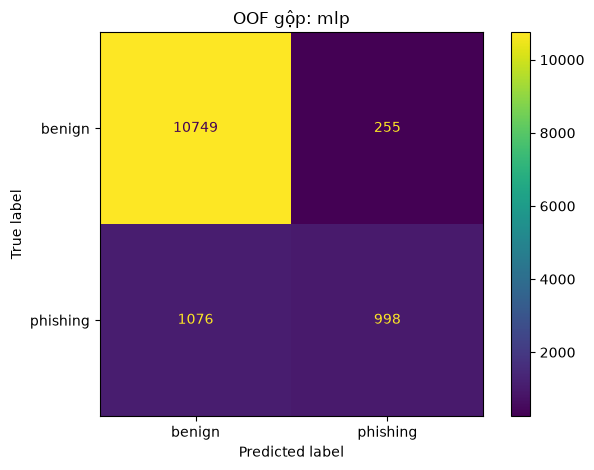

,id,fold_id,error_type,url,score,source,tier
0,0017a2da-35d5-588f-8062-349ea6be2ec7,0,FN,kokatrade[.]com,0.174662,tinnhiemmang,gold
1,0041597b-64fe-5b47-88fe-40388a88a466,0,FN,mrhmfund[.]com,0.183659,tinnhiemmang,gold
2,00c6d664-b0bd-57ac-8c17-c030f6008ff7,2,FN,vn-inc[.]info,0.373303,tinnhiemmang,gold
3,00dd46cf-3bb2-5276-b4dc-497dd8e8f9d3,1,FN,b1dv[.]xyz,0.204153,tinnhiemmang,gold
4,00f4afa6-d2b5-5e4f-b30e-c448d4fb2cbf,1,FP,https://www[.]binhthuan[.]dcs[.]vn,0.566060,tinnhiem_org,gold
5,011bd9f8-1450-5346-a9b6-638e651b6fd3,0,FP,pos365[.]vn,0.596908,tranco_vn,silver
6,018a7b82-c2cd-598a-8cfe-df160fa3f408,1,FN,masothue[.]biz,0.157950,tinnhiemmang,gold
7,01e34709-db9f-52dd-b60c-a064312ff7f4,2,FN,pinuian[.]top,0.181201,tinnhiemmang,gold
8,04dd5f6a-beae-54a3-a594-2f4af4dc75d0,0,FP,24hstore[.]vn,0.559998,tinnhiem_web,gold
9,0611f9f8-e788-5a50-9925-4aa102c7b5e5,1,FP,1001hry[.]cz,0.555225,tranco,silver


In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
for model_name, rows in cv_predictions.groupby("model"):
    precision, recall, _ = precision_recall_curve(rows["true_label"], rows["score"])
    ax.step(recall, precision, where="post", label=model_name)
ax.set(xlabel="Recall", ylabel="Precision", title="OOF gộp — chỉ minh họa")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "05_readable_pr_curve.png", dpi=140)
plt.show()

chosen = cv_predictions.loc[cv_predictions["model"].eq(selected_model)].copy()
ConfusionMatrixDisplay.from_predictions(chosen["true_label"], chosen["predicted_label"],
                                       display_labels=["benign", "phishing"])
plt.title(f"OOF gộp: {selected_model}")
plt.tight_layout()
plt.savefig(FIGURES / "05_readable_confusion.png", dpi=140)
plt.show()

errors = chosen.loc[chosen["true_label"].ne(chosen["predicted_label"])].copy()
errors["error_type"] = np.where(errors["predicted_label"].eq(1), "FP", "FN")
error_examples = errors.sort_values("id").groupby(["fold_id", "error_type"]).head(2)
error_examples = error_examples.merge(core[["id", "url", "source", "tier"]], on="id", validate="one_to_one")
# Vô hiệu hóa URL khi hiển thị; không truy cập các website này.
error_examples["url"] = error_examples["url"].str.replace(".", "[.]", regex=False)
display(error_examples[["id", "fold_id", "error_type", "url", "score", "source", "tier"]])


## 10. Lưu kết quả và model
Chỉ ghi file `05_readable_*` và `week5_readable_models.joblib`; kết quả E1/v1 không bị ghi đè. Bundle chứa model đã học, thứ tự feature và loại score. Một metadata gọn ghi tham số, phiên bản và input hashes; không có hệ thống fingerprint/audit nhiều lớp trong luồng học chính.

In [10]:
cv_metrics.to_csv(TABLES / "05_readable_cv_metrics.csv", index=False)
summary.to_csv(TABLES / "05_readable_comparison.csv", index=False)
validation_metrics.to_csv(TABLES / "05_readable_validation.csv", index=False)
pd.DataFrame(parameter_rows).to_csv(TABLES / "05_readable_parameters.csv", index=False)
error_examples.to_csv(TABLES / "05_readable_errors.csv", index=False)
cv_predictions.to_csv(DATA / "05_readable_cv_predictions.csv", index=False)
validation_predictions.to_csv(DATA / "05_readable_validation_predictions.csv", index=False)

bundle = {"models": trained_models, "selected_model": selected_model,
          "feature_names": FEATURES, "feature_set": FEATURE_SET,
          "score_kinds": {name: "decision_function" if name == "svm_rbf" else "probability" for name in models},
          "protocol": "week5_readable_v2", "decision_rule": "estimator.predict"}
model_path = MODELS_DIR / "week5_readable_models.joblib"
joblib.dump(bundle, model_path)

input_files = [DATA / "core_gold_silver.csv", FEATURE_FILE,
               DATA / "03_registrable_domains.csv", DATA / "02_group_folds_train.csv"]
notebook = nbformat.read(PROJECT_ROOT / "notebooks/05_advanced_models.ipynb", as_version=4)
training_code = "\n".join(cell.source for cell in notebook.cells if cell.cell_type == "code")
metadata = {"protocol": bundle["protocol"], "created_utc": datetime.now(timezone.utc).isoformat(),
            "primary_metric": "average_precision", "seed": SEED, "outer_folds": 3, "inner_folds": 2,
            "selected_model": selected_model, "feature_set": FEATURE_SET, "feature_names": FEATURES,
            "score_kinds": bundle["score_kinds"], "decision_rule": bundle["decision_rule"],
            "train_rows": len(train), "validation_rows": len(validation), "test_evaluated": False,
            "parameters": parameter_rows, "python": platform.python_version(),
            "versions": {name: version(name) for name in ["numpy", "pandas", "scikit-learn", "joblib"]},
            "input_sha256": {p.relative_to(PROJECT_ROOT).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest() for p in input_files},
            "notebook_code_sha256": hashlib.sha256(training_code.encode()).hexdigest(),
            "model_sha256": hashlib.sha256(model_path.read_bytes()).hexdigest()}
(TABLES / "05_readable_metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2)+"\n", encoding="utf-8")
print("Đã lưu:", model_path)


Đã lưu: D:\PhishGuardVN\models\week5_readable_models.joblib


## 11. Load và dự đoán một URL mới
Đây là kiểm tra kỹ thuật, không phải bằng chứng example.com có nhãn phishing/benign. Lúc dùng model không gọi `.fit()` nữa. `prediction.py` chỉ xử lý URL → feature → model đã học, để sau này API dùng lại được.

In [11]:
from phishguard_vn.prediction import predict_url
loaded = joblib.load(model_path)
print(predict_url("https://example.com/a", loaded))


{'model': 'mlp', 'label': 'phishing', 'score': 0.6072624063173977, 'score_kind': 'probability', 'score_definition': 'predict_proba cho phishing; chưa hiệu chuẩn nguy cơ thực tế', 'decision_rule': 'estimator.predict', 'protocol': 'week5_readable_v2'}


## 12. Đọc và phát triển tiếp
- Khi học: đọc cell 2 → 3 → 4 trước; sau đó mới đến vòng lặp cell 6/8.
- Sửa grid ở cell 3 để làm thí nghiệm mới; không dùng validation/test để quyết định grid.
- Khi Hy bàn giao brand, thống nhất `FEATURE_FILE`, `FEATURES`, phiên bản reference và extractor dự đoán trước khi mở schema mới. Không đưa source/label vào FEATURES.
- So sánh lexical và lexical+brand trên cùng samples/folds; ghi rõ phiên bản và loại score. SVM v2 không tương thích hợp đồng yêu cầu probability0.5 của bản audit cũ nếu không có adapter/protocol mới.
- Chưa chốt Teacher, chưa có KD/mobile. Phần nâng cao cũ được giữ ở `notebooks/archive/05_nested_v1.ipynb`, kết quả v1 vẫn có prefix05 cũ.
- Hướng dẫn và nhận xét: [reports/week5_readable.md](../reports/week5_readable.md).